In [4]:
#| default_exp models.ml_multi_output_forecaster

In [1]:
#| export
from __future__ import annotations
from typing import List, Dict, Optional, Callable, Tuple, Any, Union
import numpy as np
import pandas as pd
import copy
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.multioutput import MultiOutputRegressor
from peshbeen.transformations import (
    box_cox_transform, back_box_cox_transform,
    rolling_quantile, expanding_mean, expanding_std, expanding_quantile
)
from peshbeen.helpers import seasonal_diff, undiff_ts, invert_seasonal_diff
from peshbeen.model_selection import SplitTimeSeries
from peshbeen.statstools import lr_trend_model, forecast_trend
import warnings
warnings.filterwarnings("ignore")
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.compose import ColumnTransformer

class ml_multi_output_forecaster:
    def __init__(
        self,
        model: Any,
        target_cols: List[str],
        lags: Optional[Union[int, List[int], Dict[str, Union[int, List[int]]]]] = None,
        lag_transform: Optional[Dict[str, list]] = None,
        difference: Optional[Dict[str, int]] = None,
        seasonal_diff: Optional[Dict[str, int]] = None,
        trend: Optional[Dict[str, str]] = None,
        pol_degree: Optional[Union[int, Dict[str, int]]] = 1,
        ets_params: Optional[Dict[str, Any]] = None,
        change_points: Optional[Dict[str, List[int]]] = None,
        box_cox: Optional[Union[bool, float, int, Dict[str, Union[bool, float, int]]]] = None,
        box_cox_biasadj: Union[bool, Dict[str, bool]] = False,
        cat_variables: Optional[List[str]] = None,
        categorical_encoder: Optional[Union[Dict[str, Any], Any]] = None,
        verbose: bool = False,
    ) -> None:
        """
        Initialize the Multi-Output Machine Learning Forecaster with specified preprocessing and modeling parameters.

        Parameters
        ----------
        model : Any
            A scikit-learn compatible regression model object supporting multi-output targets (e.g. RandomForestRegressor(),
            ExtraTreesRegressor(), DecisionTreeRegressor(), LinearRegression(), Ridge(), XGBRegressor(),
            CatBoostRegressor(loss_function='MultiRMSE'), or MultiOutputRegressor(LGBMRegressor())).
        target_cols : List[str]
            List of target column names to model jointly as a multi-output matrix (N x m).
        lags : Optional[Union[int, List[int], Dict[str, Union[int, List[int]]]]], optional
            Lags for each target variable. Can be a dictionary keyed by target column name (values as int or list of ints),
            or a single int / list of ints applied across all target columns.
        lag_transform : Optional[Dict[str, list]], optional
            Dictionary specifying lag-transform functions for each target variable. Each value is a list of transformation
            functions (e.g., rolling_mean, expanding_std) to apply to that target.
        difference : Optional[Dict[str, int]], optional
            Dictionary specifying the order of ordinary differencing to apply to each target variable.
        seasonal_diff : Optional[Dict[str, int]], optional
            Dictionary specifying the seasonal period for seasonal differencing for each target variable.
        trend : Optional[Dict[str, str]], optional
            Dictionary specifying the trend strategy for each target variable ('linear' or 'ets').
        pol_degree : Optional[Union[int, Dict[str, int]]], default 1
            Polynomial degree for linear trend removal. Can be a single integer applied to all targets or a dictionary per target.
        ets_params : Optional[Dict[str, Any]], optional
            Dictionary specifying ETS model and fit parameters for each target variable when using 'ets' trend removal.
        change_points : Optional[Dict[str, List[int]]], optional
            Dictionary specifying change points for piecewise linear trend removal for each target variable.
        box_cox : Optional[Union[bool, float, int, Dict[str, Union[bool, float, int]]]], optional
            Whether to apply Box-Cox transformation to each target variable. Can be a bool, float, or dict keyed by target column name.
        box_cox_biasadj : Union[bool, Dict[str, bool]], default False
            Whether to apply bias adjustment when inverting the Box-Cox transformation on forecasts.
        cat_variables : Optional[List[str]], optional
            List of categorical feature column names to encode. These will be shared across all target variables.
        categorical_encoder : Optional[Union[Dict[str, Any], Any]], optional
            A categorical encoder instance, or a single-entry dictionary mapping a target column to the encoder when the encoder
            requires access to a target variable during fitting (e.g. {target_col: TargetEncoder()}).
        verbose : bool, default False
            If True, the model will print verbose messages.

        Returns
        -------
        None
        """
        if isinstance(model, type) or not (hasattr(model, "fit") and hasattr(model, "predict")):
            raise ValueError(
                "model must be an instantiated regression model object with fit() and predict() methods "
                "(e.g. RandomForestRegressor(), ExtraTreesRegressor(), LinearRegression(), XGBRegressor()). "
                "If using an external library such as lightgbm, xgboost, or catboost, make sure it is installed."
            )
        self.model = model
        self.model_name = self.model.__class__.__name__

        # Resolve base estimator name if already wrapped in MultiOutputRegressor
        if self.model_name == "MultiOutputRegressor":
            self.base_estimator_name = getattr(self.model.estimator, "__class__", type(self.model.estimator)).__name__
        else:
            self.base_estimator_name = self.model_name

        # Auto-wrap single-output models for multi-target regression if >1 target
        single_output_models = (
            "LGBMRegressor", "GradientBoostingRegressor",
            "HistGradientBoostingRegressor", "SVR", "LinearSVR",
            "AdaBoostRegressor", "SGDRegressor"
        )
        if self.base_estimator_name in single_output_models and len(target_cols) > 1 and self.model_name != "MultiOutputRegressor":
            from sklearn.multioutput import MultiOutputRegressor
            self.model = MultiOutputRegressor(self.model)
            self.model_name = "MultiOutputRegressor"

        self.target_cols = target_cols
        self.cat_variables = cat_variables
        if categorical_encoder is not None:
            if isinstance(categorical_encoder, dict):
                if len(categorical_encoder) != 1:
                    raise ValueError("If categorical_encoder is a dict, it must contain exactly one entry mapping a target column to the encoder instance.")
                encoder_target_col, encoder = next(iter(categorical_encoder.items()))
                if encoder_target_col not in self.target_cols:
                    raise ValueError("The single key in categorical_encoder must be one of target_cols.")
                self.cat_encoder_key = encoder_target_col
                self.cat_encoder = encoder
            else:
                self.cat_encoder = categorical_encoder
                self.cat_encoder_key = self.target_cols[0]
        else:
            self.cat_encoder = None

        if self.cat_variables is not None and self.cat_encoder is None:
            if self.base_estimator_name not in ["LGBMRegressor", "CatBoostRegressor", "XGBRegressor", "HistGradientBoostingRegressor"]:
                raise ValueError(
                    "Model must be LGBMRegressor, CatBoostRegressor, XGBRegressor, or HistGradientBoostingRegressor to handle categorical variables without a specified encoder "
                    "(or provide an encoder such as OneHotEncoder/TargetEncoder)."
                )
            underlying_est = self.model.estimator if isinstance(self.model, MultiOutputRegressor) else self.model
            if self.base_estimator_name == "XGBRegressor" and hasattr(underlying_est, "set_params"):
                if not getattr(underlying_est, "enable_categorical", False):
                    try:
                        underlying_est.set_params(enable_categorical=True)
                    except Exception:
                        pass
            elif self.base_estimator_name == "HistGradientBoostingRegressor" and hasattr(underlying_est, "set_params"):
                if getattr(underlying_est, "categorical_features", None) is None:
                    try:
                        underlying_est.set_params(categorical_features="from_dtype")
                    except Exception:
                        pass

        self.verbose = verbose
        self.cps = change_points

        # ── lags ──────────────────────────────────────────────────────────────
        self.n_lag: Optional[Dict[str, Union[int, List[int]]]] = None
        if lags is not None:
            self.n_lag = {}
            if isinstance(lags, int):
                for col in target_cols:
                    self.n_lag[col] = list(range(1, lags + 1))
            elif isinstance(lags, list):
                if not all(isinstance(l, int) for l in lags):
                    raise TypeError("lags list must contain only integers.")
                for col in target_cols:
                    self.n_lag[col] = lags
            elif isinstance(lags, dict):
                for col, v in lags.items():
                    if isinstance(v, int):
                        self.n_lag[col] = list(range(1, v + 1))
                    elif isinstance(v, list):
                        self.n_lag[col] = v
                    else:
                        raise TypeError(f"lags['{col}'] must be int or list of ints.")
            else:
                raise TypeError("lags must be an int, list of ints, or a dict keyed by target column name.")

        # ── lag_transform ─────────────────────────────────────────────────────
        if lag_transform is not None:
            if not isinstance(lag_transform, dict):
                raise TypeError("lag_transform must be a dict keyed by target column name.")
            self.lag_transform = lag_transform
        else:
            self.lag_transform = None

        # ── differencing ──────────────────────────────────────────────────────
        self.diffs = {col: None for col in target_cols}
        if difference is not None:
            if isinstance(difference, int):
                self.diffs = {col: (difference if difference != 0 else None) for col in target_cols}
            elif isinstance(difference, dict):
                self.diffs.update(difference)
            else:
                raise TypeError("difference must be an int or a dict keyed by target column name.")

        # ── seasonal differencing ─────────────────────────────────────────────
        self.season_diffs = {col: None for col in target_cols}
        if seasonal_diff is not None:
            if isinstance(seasonal_diff, int):
                self.season_diffs = {col: (seasonal_diff if seasonal_diff != 0 else None) for col in target_cols}
            elif isinstance(seasonal_diff, dict):
                self.season_diffs.update(seasonal_diff)
            else:
                raise TypeError("seasonal_diff must be an int or a dict keyed by target column name.")

        # ── trend ─────────────────────────────────────────────────────────────
        if isinstance(trend, str):
            self.trend = {col: trend for col in target_cols}
        elif isinstance(trend, dict):
            self.trend = trend
        elif trend is None:
            self.trend = None
        else:
            raise TypeError("trend must be a str or a dict keyed by target column name.")

        if self.trend is not None and "ets" in self.trend.values():
            CONSTRUCTOR_PARAMS = {
                "trend", "damped_trend", "seasonal", "seasonal_periods",
                "initialization_method", "initial_level", "initial_trend",
                "initial_seasonal", "bounds", "dates", "freq", "missing",
            }
            FIT_PARAMS = {
                "optimized", "smoothing_level", "smoothing_trend", "smoothing_seasonal",
                "damping_trend", "remove_bias", "start_params", "method",
                "minimize_kwargs", "use_brute",
            }

            self.ets_model: Dict[str, dict] = {}
            self.ets_fit: Dict[str, dict] = {}
            if ets_params is not None:
                if not isinstance(ets_params, dict):
                    raise TypeError("ets_params must be a dict keyed by target column name.")
                for col, ttype in self.trend.items():
                    if ttype == "ets":
                        col_params = ets_params.get(col, {})
                        if not isinstance(col_params, dict):
                            raise TypeError(f"ets_params['{col}'] must be a flat dict of ETS parameters.")
                        self.ets_model[col] = {k: v for k, v in col_params.items() if k in CONSTRUCTOR_PARAMS}
                        self.ets_fit[col]   = {k: v for k, v in col_params.items() if k in FIT_PARAMS}
            else:
                for col, ttype in self.trend.items():
                    if ttype == "ets":
                        self.ets_model[col] = {}
                        self.ets_fit[col]   = {}

        # ── polynomial degree ─────────────────────────────────────────────────
        if isinstance(pol_degree, int):
            self.pol = {col: pol_degree for col in target_cols}
        elif isinstance(pol_degree, dict):
            self.pol = {col: pol_degree.get(col, 1) for col in target_cols}
        else:
            raise ValueError("pol_degree must be an int or a dict.")

        # ── box-cox ───────────────────────────────────────────────────────────
        if isinstance(box_cox_biasadj, bool):
            self.biasadj = {col: box_cox_biasadj for col in target_cols}
        elif isinstance(box_cox_biasadj, dict):
            self.biasadj = {col: box_cox_biasadj.get(col, False) for col in target_cols}
        else:
            self.biasadj = {col: False for col in target_cols}

        if box_cox is not None:
            self.box_cox: Dict[str, bool] = {}
            self.lamdas: Dict[str, Optional[float]] = {col: None for col in target_cols}

            if isinstance(box_cox, bool):
                self.box_cox = {col: box_cox for col in target_cols}
            elif isinstance(box_cox, (float, int)):
                self.box_cox = {col: True for col in target_cols}
                self.lamdas = {col: box_cox for col in target_cols}
            elif isinstance(box_cox, dict):
                for col, val in box_cox.items():
                    if isinstance(val, bool):
                        self.box_cox[col] = val
                        self.lamdas[col] = None
                    elif isinstance(val, (float, int)):
                        self.box_cox[col] = True
                        self.lamdas[col] = val
                    else:
                        raise ValueError(
                            f"Invalid value for box_cox['{col}']: must be bool or float."
                        )
            else:
                raise TypeError(
                    "box_cox must be a bool, float, or dict keyed by target column name."
                )
        else:
            self.box_cox = box_cox

    # ─────────────────────────────────────────────────────────────────────────
    # DATA PREPARATION
    # ─────────────────────────────────────────────────────────────────────────

    def data_prep(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Apply all preprocessing transformations to df and return the cleaned DataFrame.

        Parameters
        ----------
        df : pd.DataFrame
            Input DataFrame containing the target columns and any feature columns.
        """
        dfc = df.copy()

        # ── categorical encoding ──────────────────────────────────────────────
        if self.cat_variables is not None:
            dfc = self.create_encoded_features(dfc)

        if not all(col in dfc.columns for col in self.target_cols):
            return dfc.dropna()

        self.orig_target = dfc[self.target_cols].values
        # ── Box-Cox ───────────────────────────────────────────────────────────
        if self.box_cox is not None:
            self.is_zeros: Dict[str, bool] = {}
            self.trans_data: Dict[str, np.ndarray] = {}
            for col in self.target_cols:
                if self.box_cox.get(col, False):
                    self.is_zeros[col] = (dfc[col] < 1).any()
                    trans_data, self.lamdas[col] = box_cox_transform(
                        x=dfc[col], shift=self.is_zeros[col], box_cox_lmda=self.lamdas[col]
                    )
                    dfc[col] = trans_data
                    self.trans_data[col] = trans_data

        # ── Trend removal ─────────────────────────────────────────────────────
        if self.trend is not None:
            self.len = len(df)
            self.orig_targets: Dict[str, pd.Series] = {}
            self.trend_models: Dict[str, Any] = {}

            for col, ttype in self.trend.items():
                self.orig_targets[col] = dfc[col].copy()

                if ttype == "linear":
                    bps = self.cps.get(col) if self.cps else None
                    if bps:
                        trend_vals, model_fit, _ = lr_trend_model(
                            self.orig_targets[col], degree=self.pol[col],
                            breakpoints=bps, type="piecewise"
                        )
                    else:
                        trend_vals, model_fit, _ = lr_trend_model(
                            self.orig_targets[col], degree=self.pol[col]
                        )
                    dfc[col] = dfc[col] - trend_vals
                    self.trend_models[col] = model_fit

                elif ttype == "ets":
                    model_fit = ExponentialSmoothing(
                        self.orig_targets[col], **self.ets_model[col]
                    ).fit(**self.ets_fit[col])
                    dfc[col] = dfc[col] - model_fit.fittedvalues.values
                    self.trend_models[col] = model_fit

                else:
                    raise ValueError(
                        f"Unknown trend type '{ttype}' for '{col}'. Use 'linear' or 'ets'."
                    )

        # ── Ordinary differencing ─────────────────────────────────────────────
        self.origs: Dict[str, list] = {}
        for col, d in self.diffs.items():
            if d is not None:
                self.origs[col] = dfc[col].tolist()
                dfc[col] = np.diff(dfc[col], n=d, prepend=np.repeat(np.nan, d))

        # ── Seasonal differencing ─────────────────────────────────────────────
        self.orig_ds: Dict[str, list] = {}
        for col, s in self.season_diffs.items():
            if s is not None:
                self.orig_ds[col] = dfc[col].tolist()
                dfc[col] = seasonal_diff(dfc[col], s)

        # ── Lag features ──────────────────────────────────────────────────────
        if self.n_lag is not None:
            for col, lags in self.n_lag.items():
                lag_used = lags if isinstance(lags, list) else range(1, lags + 1)
                for lg in lag_used:
                    dfc[f"{col}_lag_{lg}"] = dfc[col].shift(lg)

        # ── Lag transforms ────────────────────────────────────────────────────
        if self.lag_transform is not None:
            for idx, (col, funcs) in enumerate(self.lag_transform.items()):
                for func in funcs:
                    if isinstance(func, (expanding_std, expanding_mean)):
                        dfc[f"trg{idx}_{func.__class__.__name__}_shift_{func.shift}"] = func(dfc[col])
                    elif isinstance(func, expanding_quantile):
                        dfc[f"trg{idx}_{func.__class__.__name__}_shift_{func.shift}_q{func.quantile}"] = func(dfc[col])
                    elif isinstance(func, rolling_quantile):
                        dfc[f"trg{idx}_{func.__class__.__name__}_{func.window_size}_shift_{func.shift}_q{func.quantile}"] = func(dfc[col])
                    else:
                        dfc[f"trg{idx}_{func.__class__.__name__}_{func.window_size}_shift_{func.shift}"] = func(dfc[col])

        return dfc.dropna()

    # ─────────────────────────────────────────────────────────────────────────
    # ENCODE CATEGORICAL FEATURES
    # ─────────────────────────────────────────────────────────────────────────

    def create_encoded_features(self,
                    df: pd.DataFrame
                    ) -> pd.DataFrame:

        for col in self.cat_variables:
            df[col] = df[col].astype("category")

        if self.cat_encoder is not None:
            if all(col in df.columns for col in self.target_cols):
                num_cols = [c for c in df.columns if c not in self.cat_variables + self.target_cols]

                self.preprocess = ColumnTransformer(
                    transformers=[("cat", self.cat_encoder, self.cat_variables), ("num", "passthrough", num_cols)],
                    remainder="drop",
                    verbose_feature_names_out=False
                ).set_output(transform="pandas")

                X_train = self.preprocess.fit_transform(df.drop(columns=self.target_cols), y=df[self.cat_encoder_key])
                return pd.concat([df[self.target_cols], X_train], axis=1)

            else:
                return self.preprocess.transform(df)
        else:
            return df

    # ─────────────────────────────────────────────────────────────────────────
    # FIT
    # ─────────────────────────────────────────────────────────────────────────

    def fit(self,
            df: pd.DataFrame
            ) -> None:
        """
        Fit the multi-output model to the provided DataFrame.

        Parameters
        ----------
        df : pd.DataFrame
            Training DataFrame containing all target and feature columns.

        Returns
        -------
        None
        """
        model_df = self.data_prep(df)
        self.X = model_df.drop(columns=self.target_cols)
        self.y = np.array(model_df[self.target_cols])

        fit_kwargs = {}

        if self.base_estimator_name == "LGBMRegressor" and self.cat_encoder is None:
            fit_kwargs = {"categorical_feature": self.cat_variables}
        elif self.base_estimator_name == "CatBoostRegressor":
            underlying_est = self.model.estimator if isinstance(self.model, MultiOutputRegressor) else self.model
            if len(self.target_cols) > 1 and hasattr(underlying_est, "get_param") and underlying_est.get_param("loss_function") in (None, "RMSE"):
                underlying_est.set_params(loss_function="MultiRMSE")
            if self.cat_encoder is None:
                fit_kwargs = {"cat_features": self.cat_variables, "verbose": False}
        elif self.base_estimator_name == "XGBRegressor" and self.cat_encoder is None:
            underlying_est = self.model.estimator if isinstance(self.model, MultiOutputRegressor) else self.model
            if hasattr(underlying_est, "set_params") and not getattr(underlying_est, "enable_categorical", False):
                try:
                    underlying_est.set_params(enable_categorical=True)
                except Exception:
                    pass
        elif self.base_estimator_name == "HistGradientBoostingRegressor" and self.cat_encoder is None:
            underlying_est = self.model.estimator if isinstance(self.model, MultiOutputRegressor) else self.model
            if hasattr(underlying_est, "set_params") and getattr(underlying_est, "categorical_features", None) is None:
                try:
                    underlying_est.set_params(categorical_features="from_dtype")
                except Exception:
                    pass

        self.model_fit = self.model.fit(self.X, self.y, **fit_kwargs)

    # ─────────────────────────────────────────────────────────────────────────
    # PREDICT
    # ─────────────────────────────────────────────────────────────────────────

    def predict(self, X) -> np.ndarray:
        """
        Predict with the fitted multi-output model.

        Parameters
        ----------
        X : array-like or pd.DataFrame
            Feature vector or matrix.

        Returns
        -------
        np.ndarray
            Predicted values for each target.
        """
        return self.model_fit.predict(X)

    def predict_in_sample(self) -> None:
        """
        Generate in-sample predictions and residuals for the training data.

        Returns
        -------
        None
        """
        if not hasattr(self, "model_fit"):
            raise ValueError("Model has not been fitted yet. Call .fit() before predict_in_sample().")

        fitted_values = np.asarray(self.predict(self.X))
        if fitted_values.ndim == 1:
            fitted_values = fitted_values.reshape(-1, 1)
        fit_len = len(fitted_values)
        self.fitted_values = {col: fitted_values[:, i] for i, col in enumerate(self.target_cols)}

        self.in_samp_resids = {col: self.y[:, i] - self.fitted_values[col] for i, col in enumerate(self.target_cols)}
        self.fitted_values = {col: self.orig_target[-fit_len:, i] - self.in_samp_resids[col] for i, col in enumerate(self.target_cols)}
        if self.box_cox is not None:
            for i, col in enumerate(self.target_cols):
                if self.box_cox.get(col, False):
                    bc_fitted = self.trans_data[col][-fit_len:] - self.in_samp_resids[col]
                    self.fitted_values[col] = back_box_cox_transform(
                        y_pred=bc_fitted, lmda=self.lamdas[col],
                        shift=self.is_zeros.get(col, False), box_cox_biasadj=self.biasadj[col]
                    )
                    self.in_samp_resids[col] = self.orig_target[-fit_len:, i] - self.fitted_values[col]

    # ─────────────────────────────────────────────────────────────────────────
    # INFORMATION CRITERIA
    # ─────────────────────────────────────────────────────────────────────────

    def _k(self) -> int:
        """Number of model parameters (approximate)."""
        base = self.X.shape[1]
        if isinstance(self.model, (LinearRegression, Ridge, Lasso, ElasticNet)):
            return base + 2   # coefficients + intercept + variance
        return base + 1       # coefficients + variance

    def _ic_base(self, col: str):
        k = self._k()
        n = len(self.y)
        idx = self.target_cols.index(col)
        preds = np.asarray(self.predict(self.X))
        if preds.ndim == 1:
            preds = preds.reshape(-1, 1)
        rss = np.sum((self.y[:, idx] - preds[:, idx]) ** 2)
        return k, n, rss

    @property
    def aic(self) -> Dict[str, float]:
        """AIC per target variable."""
        out = {}
        for col in self.target_cols:
            k, n, rss = self._ic_base(col)
            out[col] = n * np.log(rss / n) + 2 * k
        return out

    @property
    def aicc(self) -> Dict[str, float]:
        """AICc per target variable."""
        out = {}
        for col in self.target_cols:
            k, n, rss = self._ic_base(col)
            aic = n * np.log(rss / n) + 2 * k
            out[col] = aic + (2 * k * (k + 1)) / (n - k - 1)
        return out

    @property
    def bic(self) -> Dict[str, float]:
        """BIC per target variable."""
        out = {}
        for col in self.target_cols:
            k, n, rss = self._ic_base(col)
            out[col] = n * np.log(rss / n) + k * np.log(n)
        return out

    @property
    def hqc(self) -> Dict[str, float]:
        """Hannan-Quinn criterion per target variable."""
        out = {}
        for col in self.target_cols:
            k, n, rss = self._ic_base(col)
            out[col] = n * np.log(rss / n) + 2 * k * np.log(np.log(n))
        return out

    def copy(self):
        return copy.deepcopy(self)

    # ─────────────────────────────────────────────────────────────────────────
    # FORECAST
    # ─────────────────────────────────────────────────────────────────────────

    def forecast(
        self,
        H: int,
        exog: Optional[pd.DataFrame] = None
    ) -> Dict[str, np.ndarray]:
        """
        Generate forecasts for H future time steps recursively across all targets simultaneously.

        Parameters
        ----------
        H : int
            Forecast horizon (number of steps ahead to predict).
        exog : Optional[pd.DataFrame], optional
            Future exogenous regressors (must contain at least H rows).

        Returns
        -------
        Dict[str, np.ndarray]
            Forecasted values for each target, keyed by column name.
        """
        # Rolling history for each target
        y_lists: Dict[str, list] = {
            col: self.y[:, i].tolist()
            for i, col in enumerate(self.target_cols)
        }

        # ── Prepare exog ──────────────────────────────────────────────────────
        if exog is not None:
            if self.cat_variables is not None:
                exog = self.data_prep(exog)

        # ── Pre-compute trend forecasts ───────────────────────────────────────
        trend_forecasts: Dict[str, np.ndarray] = {}

        if self.trend is not None:
            for col, ttype in self.trend.items():
                if ttype == "linear":
                    bps = self.cps.get(col) if self.cps else None
                    trend_forecasts[col], _ = forecast_trend(
                        model=self.trend_models[col], H=H,
                        start=self.len, degree=self.pol[col], breakpoints=bps
                    )
                elif ttype == "ets":
                    trend_forecasts[col] = np.array(self.trend_models[col].forecast(H))

        # ── Recursive forecast loop ───────────────────────────────────────────
        raw_forecasts: Dict[str, list] = {col: [] for col in self.target_cols}

        for t in range(H):
            # Exogenous features for step t
            exo_inp = exog.iloc[t, :].tolist() if exog is not None else []

            # Lag features
            inp_lag = []
            if self.n_lag is not None:
                for col, lags in self.n_lag.items():
                    lag_used = lags if isinstance(lags, list) else range(1, lags + 1)
                    inp_lag.extend([y_lists[col][-x] for x in lag_used])

            # Lag-transform features
            transform_lag = []
            if self.lag_transform is not None:
                for col, funcs in self.lag_transform.items():
                    series_array = np.array(y_lists[col])
                    for func in funcs:
                        transform_lag.append(func(series_array, is_forecast=True).to_numpy()[-1])

            inp = exo_inp + inp_lag + transform_lag
            df_inp = pd.DataFrame([inp], columns=self.X.columns)

            if (self.base_estimator_name in ["LGBMRegressor", "CatBoostRegressor", "XGBRegressor", "HistGradientBoostingRegressor"]) and self.cat_encoder is None:
                for c in df_inp.columns:
                    if c in (self.cat_variables or []):
                        df_inp[c] = df_inp[c].astype(self.X[c].dtype if hasattr(self, "X") and c in self.X.columns and isinstance(self.X[c].dtype, pd.CategoricalDtype) else "category")
                    else:
                        df_inp[c] = df_inp[c].astype("float64")

            pred = np.asarray(self.predict(df_inp)).ravel()

            for i, col in enumerate(self.target_cols):
                raw_forecasts[col].append(pred[i])
                y_lists[col].append(pred[i])

        # ── Post-processing ───────────────────────────────────────────────────
        forecasts: Dict[str, np.ndarray] = {
            col: np.array(raw_forecasts[col]) for col in self.target_cols
        }

        # Add back removed trend
        if self.trend is not None:
            for col in self.trend:
                forecasts[col] = forecasts[col] + trend_forecasts[col]

        # Invert seasonal differencing
        for col, s in self.season_diffs.items():
            if s is not None:
                forecasts[col] = invert_seasonal_diff(self.orig_ds[col], forecasts[col], s)

        # Invert ordinary differencing
        for col, d in self.diffs.items():
            if d is not None:
                forecasts[col] = undiff_ts(self.origs[col], forecasts[col], d)

        # Non-negativity
        for col in forecasts:
            forecasts[col] = np.array([max(0, x) for x in forecasts[col]])

        # Invert Box-Cox
        if self.box_cox is not None:
            for col in self.target_cols:
                if self.box_cox.get(col, False):
                    forecasts[col] = back_box_cox_transform(
                        y_pred=forecasts[col],
                        lmda=self.lamdas[col],
                        shift=self.is_zeros.get(col, False),
                        box_cox_biasadj=self.biasadj[col]
                    )

        return forecasts

    def cross_validate(
        self,
        df: pd.DataFrame,
        cv_split: int,
        test_size: int,
        metrics: List[Callable],
        step_size: Optional[int] = None,
        h_split_point: Optional[int] = None,
    ) -> pd.DataFrame:
        """
        Expanding-window cross-validation evaluated across all target variables.

        Parameters
        ----------
        df : pd.DataFrame
            Input DataFrame containing all target variables and any feature columns.
        cv_split : int
            Number of cross-validation folds.
        test_size : int
            Test size (forecast horizon) per fold.
        metrics : List[Callable]
            Metric functions (e.g. ``[WMAPE, MAE, RMSE, MASE]``) used to evaluate forecast accuracy across folds.
            Access ``.cv_summary`` after cross-validation to retrieve the aggregated scores across all target variables.
        step_size : int, optional
            Step size for expanding window. If None, defaults to test_size.
        h_split_point : int, optional
            Point to split the test set for separate evaluation. Default is None.

        Returns
        -------
        pd.DataFrame
            DataFrame containing detailed cross-validation results with columns: fold, target, cutoff_date, horizon, y_true, y_pred.
        """
        tscv = SplitTimeSeries(n_splits=cv_split, test_size=test_size, step_size=step_size)
        if not isinstance(metrics, (list, tuple)):
            metrics = [metrics]
        metric_names = [getattr(m, "__name__", m.__class__.__name__) for m in metrics]
        rows = []
        fold_scores = {mname: {col: [] for col in self.target_cols} for mname in metric_names}
        if h_split_point is not None and isinstance(h_split_point, int):
            fold_scores_p1 = {mname: {col: [] for col in self.target_cols} for mname in metric_names}
            fold_scores_p2 = {mname: {col: [] for col in self.target_cols} for mname in metric_names}

        for fold, (train_index, test_index) in enumerate(tscv.split(df)):
            train, test = df.iloc[train_index], df.iloc[test_index]
            cutoff = train.index[-1]
            x_test = test.drop(columns=self.target_cols)
            exog_t = x_test if x_test.shape[1] > 0 else None

            forecaster = copy.deepcopy(self)
            forecaster.fit(train)
            all_forecasts = forecaster.forecast(test_size, exog_t)

            for col in self.target_cols:
                y_true = np.asarray(test[col].values)
                y_pred = np.asarray(all_forecasts[col][:len(y_true)])
                y_train = np.asarray(train[col].values)

                for h_idx, (yt, yp) in enumerate(zip(y_true, y_pred)):
                    rows.append({
                        "fold": fold + 1,
                        "target": col,
                        "cutoff_date": cutoff,
                        "horizon": h_idx + 1,
                        "y_true": yt,
                        "y_pred": yp,
                    })

                for mfunc, mname in zip(metrics, metric_names):
                    if mname in ["MASE", "SMAE", "SRMSE", "RMSSE"]:
                        score = mfunc(y_true, y_pred, y_train)
                    else:
                        score = mfunc(y_true, y_pred)
                    fold_scores[mname][col].append(score)

                    if h_split_point is not None and isinstance(h_split_point, int):
                        y_t1, y_t2 = y_true[:h_split_point], y_true[h_split_point:]
                        y_p1, y_p2 = y_pred[:h_split_point], y_pred[h_split_point:]
                        if mname in ["MASE", "SMAE", "SRMSE", "RMSSE"]:
                            s1 = mfunc(y_t1, y_p1, y_train)
                            s2 = mfunc(y_t2, y_p2, y_train)
                        else:
                            s1 = mfunc(y_t1, y_p1)
                            s2 = mfunc(y_t2, y_p2)
                        fold_scores_p1[mname][col].append(s1)
                        fold_scores_p2[mname][col].append(s2)

        df_detailed = pd.DataFrame(rows)

        summary_dict = {}
        for col in self.target_cols:
            summary_dict[col] = {mname: np.mean(fold_scores[mname][col]) for mname in metric_names}
        summary_dict["overall"] = {
            mname: np.mean([np.mean(fold_scores[mname][col]) for col in self.target_cols])
            for mname in metric_names
        }
        self.cv_summary = pd.DataFrame(summary_dict)

        if h_split_point is not None and isinstance(h_split_point, int):
            p1_dict = {col: {mname: np.mean(fold_scores_p1[mname][col]) for mname in metric_names} for col in self.target_cols}
            p1_dict["overall"] = {mname: np.mean([np.mean(fold_scores_p1[mname][col]) for col in self.target_cols]) for mname in metric_names}
            p2_dict = {col: {mname: np.mean(fold_scores_p2[mname][col]) for mname in metric_names} for col in self.target_cols}
            p2_dict["overall"] = {mname: np.mean([np.mean(fold_scores_p2[mname][col]) for col in self.target_cols]) for mname in metric_names}
            self.cv_summary_split = {
                f"1-{h_split_point}": pd.DataFrame(p1_dict),
                f"{h_split_point+1}-{test_size}": pd.DataFrame(p2_dict),
            }

        return df_detailed

    def get_name(self):
        return "ml_multi_output_forecaster"


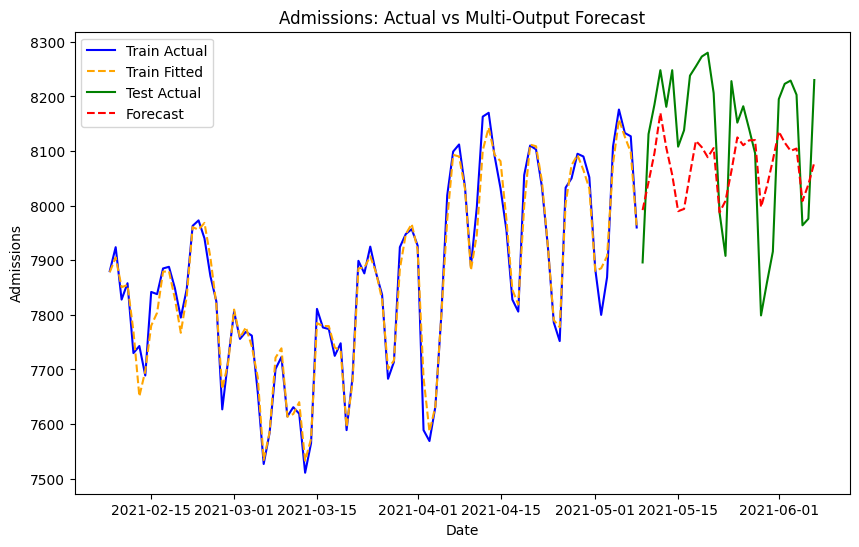

In [2]:
#| hide

from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.ensemble import RandomForestRegressor
## import linear and ridge regressors
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from peshbeen.datasets import load_admission_calls

ohe = OneHotEncoder(drop="first", sparse_output=False)
te = TargetEncoder(target_type="continuous")

admission_calls = load_admission_calls()
admission_calls["day_of_week"] = admission_calls.index.dayofweek
admission_calls["month"] = admission_calls.index.month
train = admission_calls[:-30]
test = admission_calls[-30:]

cat_variables = ["day_of_week", "month"]

mo_model = ml_multi_output_forecaster(
    model=LGBMRegressor(verbose=-1),
    target_cols=["admissions", "calls"],
    lags={"admissions": 7, "calls": 7},
    box_cox={"admissions": False, "calls": False},
    cat_variables=cat_variables,
    categorical_encoder=ohe,
    box_cox_biasadj=True
)

mo_model.fit(train)
mo_model.predict_in_sample()
forecasts = mo_model.forecast(H=30, exog=test[cat_variables])

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(train.index[-90:], train["admissions"][-90:], label="Train Actual", color="blue")
plt.plot(train.index[-90:], mo_model.fitted_values["admissions"][-90:], label="Train Fitted", color="orange", linestyle="--")
plt.plot(test.index, test["admissions"], label="Test Actual", color="green")
plt.plot(test.index, forecasts["admissions"], label="Forecast", color="red", linestyle="--")
plt.xlabel("Date")
plt.ylabel("Admissions")
plt.title("Admissions: Actual vs Multi-Output Forecast")
plt.legend()
plt.show()


In [3]:
#| hide

from peshbeen.metrics import WMAPE, MAE, RMSE
mtrcs = [WMAPE, MAE, RMSE]
cvdf = mo_model.cross_validate(df=admission_calls, cv_split=3, test_size=30, metrics=mtrcs, h_split_point=15)
mo_model.cv_summary


,admissions,calls,overall
WMAPE,0.019131,0.045292,0.032212
MAE,152.361479,58.911687,105.636583
RMSE,177.799646,77.721085,127.760366
